# T1.1 NRCS

**Purpose** (Table 4.2, D-5 validation plan): the reference SWB simulation provides the NRCS used in all SWB-SCA analyses.
The low-pass filtered (LPF) SCA NRCS is compared to the NRCS expected under the same viewing geometry from a conventional Geophysical Model Function (GMF).

**Implementation**
1. Estimate SCA-NRCS from SWB-NRCS (azimuthal beam integration with the EUMETSAT beam pattern)
2. LPF SCA-NRCS to the product resolution (50 km)
3. LPF SWB wind field to the same resolution
4. Estimate GMF NRCS from the LPF SWB wind field, with CMOD5.N (Hersbach, 2010)
5. Compare GMF NRCS with LPF SCA-NRCS

**Requirements**: reference simulations SWB-SCA (California, MED-1, MED-2), NRCS GMF (CMOD5.N)

This notebook performs the test and reports the results for interpretation. No tolerances or pass/fail criteria are applied.

**Notes**
- 50 km is the product resolution (about one independent sample per 25 km), not the 25 km of conventional wind products.
- The SWB (stress-equivalent) wind is used as the CMOD5.N input.
- Wind direction: in GMF_SWB and the uncertainty notebooks, `wdir_wrt_sensor` = 0 is the wind blowing away from the sensor and 180 towards it.
  CMOD5.N's $\phi$ = 0 is upwind, i.e. the wind blowing towards the radar, so $\phi$ = `wdir_wrt_sensor` + 180. Section 2 checks this against the SWB NRCS.

In [1]:
import numpy as np
import xarray as xr
import pandas as pd
from matplotlib import pyplot as plt

from sca_module.readers import create_dataset
from sca_module.dopsca_setup import DopSCAConfig
from sca_module.simulate_L1 import compute_cube_observation_geometry, compute_observations, create_observation_cube, compute_lpf_cube
from leakage.conversions import dB, angular_difference, dir_from_u_v, magnitude_from_u_v, convert_to_0_360
from stereoid.oceans.forward_models.cmod5n import cmod5n_forward

func_bias = lambda x, rounding=3:  np.round(np.nanmean(x), rounding)

plt.rcParams.update({'font.size': 10, 'font.weight' : 'bold'})

# Data preparation
## 0 - Parameters

In [2]:
sca = DopSCAConfig()
sca.Lambda = sca.get_wavelength()
# The magic_divider is an unnecessary, but convenient, method to resample the input data to some common sampling.
# This prevents aliasing in azimuth, and does not remove range resolution
sca.grid_spacing_target = sca.get_grid_spacing_target(magic_divider=2)

## 1 - Load SWB simulations

In [3]:
files = {
    "California": [
        '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_input_California.nc',
        '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_output_California.nc'
    ],
    "MED-1": [
        '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_input_med_orb70_2022-01-20T18.nc',
        '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_output_med_orb70_2022-01-20T18.nc'
    ],
    "MED-2": [
        '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_input_med_orb70_2022-01-22T18.nc',
        '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_output_med_orb70_2022-01-22T18.nc'
    ],
}

# California is kept over its full swath. The Mediterranean cases are cropped to avoid the regions where the SWB fails
domains = {
    "California": dict(),
    "MED-1": dict(grg = slice(590E3, 742E3), az = slice(50E3, 350E3)),
    "MED-2": dict(grg = slice(590E3, 742E3), az = slice(50E3, 350E3)),
}

# reload interpolated beam pattern received from EUMETSAT
beam_SCA = xr.open_dataset('/Users/opodriscoll/Documents/projects/DopSCA MOMS/data/beam_pattern_updated.nc')['beam_sca']

In [4]:
simulations = {}
for case in files:
    simulation = xr.open_mfdataset(files[case], compat='no_conflicts', engine='netcdf4').sel(sat = 'S1').drop_vars('bist_ang').compute()
    sca.magic_offset = sca.get_magic_offset(incidence_min=simulation.inc.min().data)

    # clipping unreasonable incidence angles
    simulation = simulation.sel(grg = slice(sca.grg_min - sca.magic_offset, sca.grg_max - sca.magic_offset))
    simulation = simulation.assign_coords(grg = simulation.grg + sca.magic_offset)

    # Here we interpolate to finer grid spacing,
    new_az = np.arange(simulation.az.min(), simulation.az.max(), sca.grid_spacing_target)
    new_grg = np.arange(simulation.grg.min(), simulation.grg.max(), sca.grid_spacing_target)
    simulation = simulation.interp(az=new_az, grg=new_grg)
    simulation = simulation.sel(domains[case])

    # wind speed and direction w.r.t. the sensor at the native resolution
    # 0 & 360 is blowing away from the sensor, 180 is blowing towards (convention of GMF_SWB)
    simulation['wspd'] = magnitude_from_u_v(u=simulation['wnd_u'], v=simulation['wnd_v'])
    simulation['wdir'] = dir_from_u_v(u=simulation['wnd_u'], v=simulation['wnd_v'])
    sensor_dir = 90 # assuming right looking
    simulation['wdir_wrt_sensor'] = convert_to_0_360(angular_difference(sensor_dir, np.rad2deg(simulation['wdir'])))

    simulations[case] = simulation

## 2 - CMOD5.N and its wind-direction convention
CMOD5.N's $\phi$ is the angle between the radar look direction and the direction the wind comes from: $\phi$ = 0 is upwind (wind blowing towards the radar), where the NRCS is largest.

In [5]:
# an xarray-friendly wrapper for the CMOD5.N forward model
def cmod5n(wspd, wdir_wrt_sensor, inc, phi_offset = 180):
    """
    CMOD5.N NRCS (linear units) for xarray inputs, broadcast against each other

    wdir_wrt_sensor follows the GMF_SWB convention (0 is blowing away from the sensor), inc is in degrees.
    CMOD5.N's phi = 0 is the wind blowing towards the radar, hence the default phi_offset of 180 degrees
    """
    wspd, phi, inc = xr.broadcast(wspd, convert_to_0_360(wdir_wrt_sensor + phi_offset), inc)
    nrcs = cmod5n_forward(wspd.to_numpy().ravel(), phi.to_numpy().ravel(), inc.to_numpy().ravel())
    return xr.DataArray(nrcs.reshape(wspd.shape), dims=wspd.dims, coords=wspd.coords)

## 3 - Estimate SCA-NRCS from SWB-NRCS (step 1)
Noise-free beam integration along azimuth with the EUMETSAT beam pattern: `nrcs_scat`.

In [6]:
VARS_SCA = ["nrcs_scat", "inc_scat"]

observations = {}
for case, simulation in simulations.items():
    nrcs = simulation[sca.var_nrcs].sel(pol='M')
    dop = simulation[sca.var_dop].sel(pol='M')
    inc_2d = np.degrees(simulation[sca.var_inc].expand_dims(dim={sca.dim_az: simulation.az.data}))

    data = create_dataset(
        nrcs=nrcs.data,
        dop=dop.data,
        inc=inc_2d.data,
        grg=simulation.grg.data,
        az=simulation.az.data,
        grid_spacing=sca.grid_spacing_target,
    )

    data_cube = create_observation_cube(data, sca.az_footprint_cutoff, sca.grid_spacing_target, sca.v_sat_ground, sca.PRF, dropna=False).compute()
    data_cube = compute_cube_observation_geometry(data_cube, sca.dim_az_beam, sca.dim_az_slow_time, sca.dim_range, sca.var_inc, sca.z0, sca.boresight_elevation_angle_scat)

    data_cube = data_cube.transpose(sca.dim_az_slow_time, sca.dim_az_beam, sca.dim_range)
    data_cube['beam']= beam_SCA.interp(az_beam=data_cube.az_beam, grg=data_cube.grg, method='linear')

    data_cube = compute_observations(data_cube, sca.var_nrcs, sca.var_inc, sca.dim_az_beam, sca.v_sat_orbit, sca.Lambda, sca.T_pp, var_azimuth_angle_wrt_boresight = "az_angle_wrt_boresight_ground")

    # only the beam-integrated fields are kept, the cube itself is large
    observations[case] = data_cube[VARS_SCA].transpose(sca.dim_az_slow_time, sca.dim_range).compute()
    observations[case].attrs["stride"] = data_cube.attrs["stride"]

## 4 - LPF SCA-NRCS to the product resolution (step 2)

In [7]:
for case, obs in observations.items():
    observations[case] = compute_lpf_cube(
        obs,
        resolution_product= sca.resolution_product,
        fs_x=1 / obs.attrs["stride"],
        fs_y=1 / sca.grid_spacing_target,
        data_2_lpf=["nrcs_scat"],
        window=sca.product_averaging_window,
        crop_edges = True,
        min_footprint_coverage = 1, # only product cells whose whole footprint is available
    )

## 5 - LPF SWB wind field to the product resolution (step 3)
The wind is filtered over the same azimuthal extent as the SCA NRCS. The beam integration shortens that extent by the footprint (+- 40 km), 
and near the edges the filter only averages over the available samples, so both fields must share the same edges.

In [8]:
for case, simulation in simulations.items():
    # crop to the azimuthal extent of the SCA observations, which the beam integration shortens by the footprint.
    # Near the edges the filter only averages over the available samples, so both fields must share the same edges
    az_sca, stride = observations[case][sca.dim_az_slow_time], observations[case].attrs["stride"]
    simulation = simulation.sel({sca.dim_az: slice(az_sca.min().item() - stride / 2, az_sca.max().item() + stride / 2)})

    data_2_lpf : list[str] = ["wnd_u", "wnd_v"]
    names_lpf_vars = [i+'_lpf' for i in data_2_lpf]
    coords_to_drop = (set(simulation.coords) - set(list(simulation[data_2_lpf[0]].dims)))

    # NOTE fs_x is the sampling along the first dimension (az), fs_y along the second (grg)
    simulation[names_lpf_vars] = compute_lpf_cube(
        ds_cube = simulation.drop_vars(coords_to_drop)[data_2_lpf],
        fs_x = 1 / sca.grid_spacing_target,
        fs_y = 1 / sca.grid_spacing_target,
        resolution_product = sca.resolution_product,
        data_2_lpf = data_2_lpf,
        window = sca.product_averaging_window,
        crop_edges = True,
        min_footprint_coverage = 1, # only product cells whose whole footprint is available
    )[names_lpf_vars]

    simulation['wspd_lpf'] = magnitude_from_u_v(u=simulation['wnd_u_lpf'], v=simulation['wnd_v_lpf'])
    simulation['wdir_lpf'] = dir_from_u_v(u=simulation['wnd_u_lpf'], v=simulation['wnd_v_lpf'])
    simulation['wdir_wrt_sensor_lpf'] = convert_to_0_360(angular_difference(sensor_dir, np.rad2deg(simulation['wdir_lpf'])))
    simulations[case] = simulation

## 6 - Estimate GMF NRCS (step 4)
CMOD5.N of the LPF SWB wind, on the SCA product grid.

In [9]:
comparisons = {}
for case, simulation in simulations.items():
    obs = observations[case]

    on_sca_grid = simulation[['wspd_lpf', 'wdir_wrt_sensor_lpf']].reset_coords(drop=True).interp(
        {sca.dim_az: obs[sca.dim_az_slow_time], sca.dim_range: obs[sca.dim_range]}
    )

    comparison = xr.Dataset({
        "nrcs_sca": obs['nrcs_scat_lpf'],
        "nrcs_cmod": cmod5n(on_sca_grid['wspd_lpf'], on_sca_grid['wdir_wrt_sensor_lpf'], obs['inc_scat']),
    })

    # both fields are evaluated over the same product cells
    evaluate = comparison['nrcs_sca'].notnull() & comparison['nrcs_cmod'].notnull()
    comparisons[case] = comparison.where(evaluate)

## 7 - Compare GMF NRCS with LPF SCA-NRCS (step 5)
Difference in dB: SCA - CMOD5.N(LPF wind)

In [10]:
for case, comparison in comparisons.items():
    comparison['diff'] = dB(comparison['nrcs_sca']) - dB(comparison['nrcs_cmod'])

# Results
## Summary
Bias is the mean difference SCA - CMOD5.N(LPF wind), in dB.

In [11]:
summary = pd.DataFrame(
    {"bias [dB]": [func_bias(comparison['diff']) for comparison in comparisons.values()]},
    index=pd.Index(list(comparisons), name="case"),
)
summary

,bias [dB]
case,
California,0.064
MED-1,-0.210
MED-2,-0.210


## Maps
LPF SCA-NRCS, CMOD5.N of the LPF wind, and their difference, on the product cells evaluated.

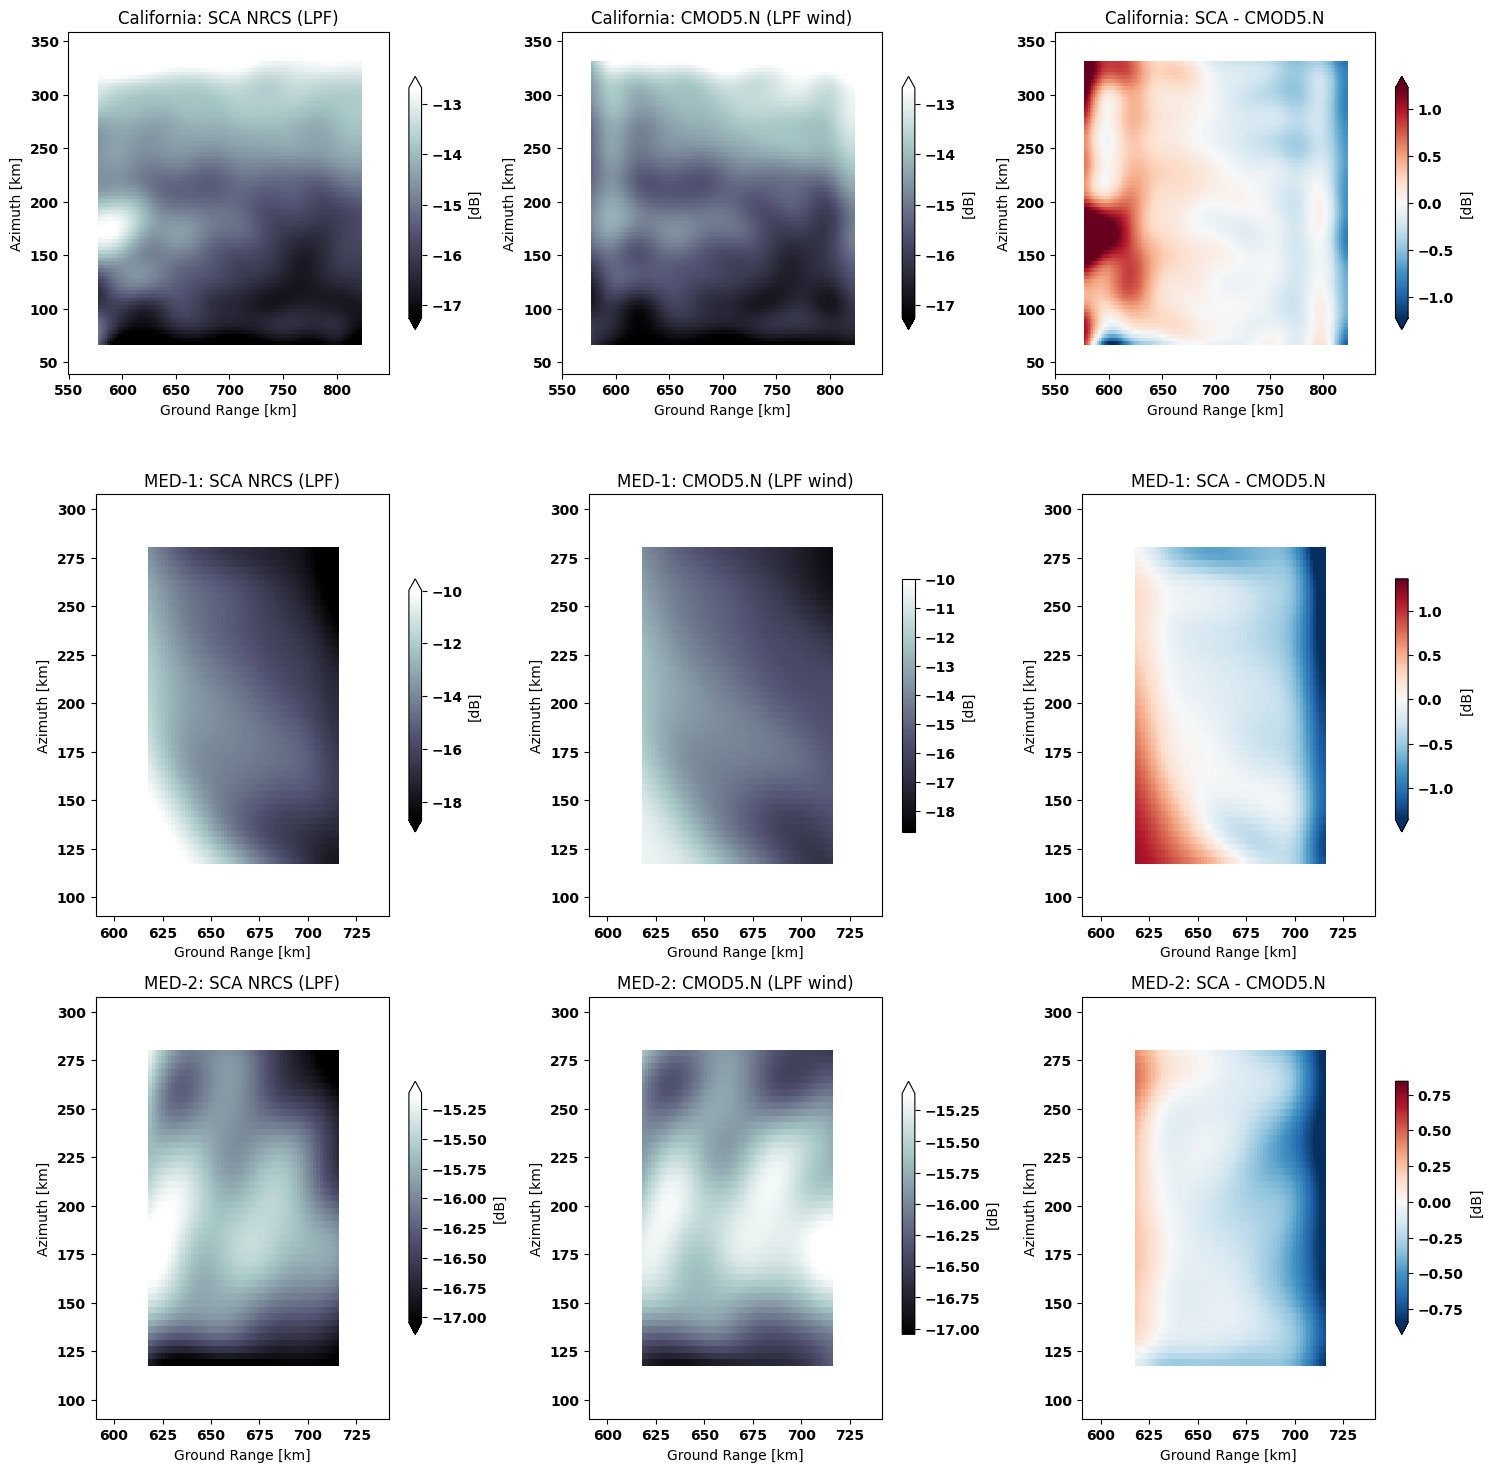

In [12]:
fig, axes = plt.subplots(ncols=3, nrows=len(comparisons), figsize = (15, 5 * len(comparisons)), squeeze=False)

for i, (case, comparison) in enumerate(comparisons.items()):
    c = comparison.assign_coords({sca.dim_range: comparison[sca.dim_range] / 1e3, sca.dim_az_slow_time: comparison[sca.dim_az_slow_time] / 1e3})
    vmin, vmax = np.nanpercentile(dB(c['nrcs_sca']), [2, 98])
    dB(c['nrcs_sca']).plot(ax = axes[i, 0], x=sca.dim_range, cmap = 'bone', vmin=vmin, vmax=vmax, cbar_kwargs={"label": "[dB]", "shrink" : 0.6})
    dB(c['nrcs_cmod']).plot(ax = axes[i, 1], x=sca.dim_range, cmap = 'bone', vmin=vmin, vmax=vmax, cbar_kwargs={"label": "[dB]", "shrink" : 0.6})
    lim = np.nanpercentile(abs(c['diff']), 98)
    c['diff'].plot(ax = axes[i, 2], x=sca.dim_range, cmap = 'RdBu_r', vmin=-lim, vmax=lim, cbar_kwargs={"label": "[dB]", "shrink" : 0.6})

    _ = axes[i, 0].set_title(f"{case}: SCA NRCS (LPF)")
    _ = axes[i, 1].set_title(f"{case}: CMOD5.N (LPF wind)")
    _ = axes[i, 2].set_title(f"{case}: SCA - CMOD5.N")

for ax in axes.flatten():
    ax.set_aspect('equal')
    ax.set_xlabel("Ground Range [km]")
    ax.set_ylabel("Azimuth [km]")
fig.tight_layout()